# Sprint 15 · Proyecto guiado
## Predicción del precio de coches usados · Rusty Bargain

**Duración:** 90 minutos  
**Modalidad:** Coding Together  
**Nivel:** principiante

Esta sesión está dedicada únicamente al proyecto.

La teoría de métodos numéricos aparece solo cuando necesitamos justificar una decisión.

## Objetivos de aprendizaje

Al finalizar la clase, el estudiante podrá:

1. transformar un problema de negocio en un problema de regresión;
2. preparar variables numéricas y categóricas;
3. separar correctamente train, validación y test;
4. establecer una línea base;
5. entrenar y comparar modelos mediante **RMSE**;
6. medir tiempo de entrenamiento y tiempo de predicción;
7. comparar un método lineal directo, un método iterativo y boosting;
8. seleccionar un modelo con validación;
9. evaluar una sola vez el modelo final sobre test;
10. redactar una recomendación técnica para el negocio.

## Entregable

Al finalizar tendremos:

- datos preparados para modelar;
- una línea base;
- Regresión Lineal;
- varias configuraciones de `SGDRegressor`;
- Gradient Boosting;
- tabla comparativa de calidad y tiempos;
- modelo final evaluado sobre test;
- recomendación para Rusty Bargain.

## Agenda · 90 minutos

| Tiempo | Bloque |
|---:|---|
| 0–5 min | Caso de negocio y criterio de éxito |
| 5–15 min | Carga e inspección |
| 15–25 min | Limpieza |
| 25–35 min | Features, target y codificación |
| 35–43 min | Train / validación / test + escalado |
| 43–50 min | Baseline |
| 50–60 min | Regresión lineal |
| 60–70 min | SGD |
| 70–80 min | Gradient Boosting |
| 80–86 min | Comparación y selección |
| 86–90 min | Test y recomendación |

# 0. Caso de negocio

Rusty Bargain quiere una aplicación que permita estimar rápidamente el precio de mercado de un coche usado.

El negocio valora tres cosas:

1. **calidad de la predicción**;
2. **velocidad de predicción**;
3. **tiempo de entrenamiento**.

### Pregunta para el grupo

Si dos modelos tienen prácticamente la misma calidad, pero uno tarda 20 veces más en predecir:

**¿cuál preferirías para una aplicación que responde al usuario en tiempo real?**

# 1. Preparar el entorno

In [1]:
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)

def calcular_rmse(y_real, y_predicho):
    return np.sqrt(mean_squared_error(y_real, y_predicho))

print("Librerías importadas correctamente")

Librerías importadas correctamente


# 2. Cargar los datos

El notebook buscará primero:

`sprint15_used_cars_teaching.csv`

También acepta el nombre original del archivo adjunto con `(1)`.

In [4]:
df = pd.read_csv('sprint15_used_cars_teaching.csv')

print("Dimensiones:", df.shape)
display(df.head())

Dimensiones: (3200, 16)


,DateCrawled,Price,VehicleType,RegistrationYear,Gearbox,Power,Model,Mileage,RegistrationMonth,FuelType,Brand,NotRepaired,DateCreated,NumberOfPictures,PostalCode,LastSeen
0,2026-03-06,14983,suv,2010,manual,101,corolla,187000,12,electric,toyota,no,2026-06-14,0,13743,2026-06-29
1,2026-04-12,7943,sedan,2006,manual,176,NaN,217000,2,diesel,mercedes,no,2026-01-22,0,71442,2026-04-23
2,2026-06-08,400,suv,1997,NaN,124,polo,203000,12,gasoline,volkswagen,no,2026-04-05,0,44506,2026-06-27
3,2026-01-21,400,sedan,1998,automatic,103,rav4,238000,11,diesel,toyota,no,2026-05-22,0,63897,2026-04-09
4,2026-04-20,17289,suv,2006,manual,180,q3,158000,8,diesel,audi,no,2026-05-28,0,86193,2026-06-03


# 3. Inspección mínima

No haremos una EDA extensa.

Para modelar necesitamos responder:

- ¿cuántas filas y columnas tenemos?
- ¿qué columna queremos predecir?
- ¿hay nulos?
- ¿qué variables parecen numéricas?
- ¿qué variables parecen categóricas?

In [6]:
print("Tipos de datos")
display(df.dtypes.to_frame("tipo"))

print("\nValores nulos")
display(df.isna().sum())

print("\nResumen numérico")
display(df[["Price", "RegistrationYear", "Power", "Mileage"]].describe())

Tipos de datos


,tipo
DateCrawled,object
Price,int64
VehicleType,object
RegistrationYear,int64
Gearbox,object
Power,int64
Model,object
Mileage,int64
RegistrationMonth,int64
FuelType,object



Valores nulos


DateCrawled            0
Price                  0
VehicleType          128
RegistrationYear       0
Gearbox               80
Power                  0
Model                112
Mileage                0
RegistrationMonth      0
FuelType              96
Brand                  0
NotRepaired          192
DateCreated            0
NumberOfPictures       0
PostalCode             0
LastSeen               0
dtype: int64


Resumen numérico


,Price,RegistrationYear,Power,Mileage
count,"3,200.00","3,200.00","3,200.00","3,200.00"
mean,"11,082.58","2,007.26",123.76,"189,928.12"
std,"11,411.43",12.67,45.37,"89,478.16"
min,0.00,"1,900.00",0.00,"5,000.00"
25%,400.00,"2,000.00",94.00,"112,000.00"
50%,"7,664.00","2,008.00",122.00,"193,000.00"
75%,"20,983.25","2,016.00",154.00,"284,000.00"
max,"48,084.00","2,024.00",306.00,"300,000.00"


### Pregunta

Nuestra variable objetivo será `Price`.

¿Estamos ante clasificación o regresión?

<details>
<summary><strong>Respuesta</strong></summary>

Regresión, porque queremos predecir un valor numérico continuo: el precio.

</details>

# 4. Limpieza

Aplicaremos reglas sencillas y explícitas.

Para una clase de 90 minutos no intentaremos resolver todos los casos de calidad de datos.

Conservaremos:

- precios positivos;
- años entre 1980 y 2025;
- potencia entre 30 y 500.

En las variables categóricas reemplazaremos nulos por `unknown`.

In [7]:
df_limpio = df.copy()

df_limpio = df_limpio[
    (df_limpio["Price"] > 0) &
    (df_limpio["RegistrationYear"].between(1980, 2025)) &
    (df_limpio["Power"].between(30, 500))
].copy()

columnas_categoricas = [
    "VehicleType",
    "Gearbox",
    "FuelType",
    "Brand",
    "NotRepaired"
]

for columna in columnas_categoricas:
    df_limpio[columna] = df_limpio[columna].fillna("unknown")

print("Filas originales:", len(df))
print("Filas después de reglas de limpieza:", len(df_limpio))

Filas originales: 3200
Filas después de reglas de limpieza: 3115


## ¿Por qué no usamos todas las columnas?

Algunas columnas son metadatos y no aportan de forma clara al objetivo didáctico:

- `DateCrawled`;
- `DateCreated`;
- `LastSeen`;
- `PostalCode`;
- `NumberOfPictures`.

También omitiremos `Model` en esta versión para mantener el One-Hot Encoding manejable y el código fácil de explicar.

> En un proyecto real, excluir una variable debe justificarse y podría revisarse experimentalmente.

# 5. Features y target

Elegiremos cuatro variables numéricas y cinco categóricas.

In [8]:
columnas_numericas = [
    "RegistrationYear",
    "Power",
    "Mileage",
    "RegistrationMonth"
]

features = columnas_numericas + columnas_categoricas

X = df_limpio[features].copy()
y = df_limpio["Price"].copy()

print("Features:", features)
print("X:", X.shape)
print("y:", y.shape)

Features: ['RegistrationYear', 'Power', 'Mileage', 'RegistrationMonth', 'VehicleType', 'Gearbox', 'FuelType', 'Brand', 'NotRepaired']
X: (3115, 9)
y: (3115,)


# 6. One-Hot Encoding

Los modelos necesitan una representación numérica.

`Brand`, `Gearbox`, `FuelType`, etc. son categorías sin una escala numérica natural.

Usaremos `pd.get_dummies()`.

Ejemplo:

`Gearbox = manual / automatic`

puede convertirse en columnas 0/1.

In [9]:
X_codificado = pd.get_dummies(
    X,
    columns=columnas_categoricas,
    dtype=float
)

print("Columnas antes:", X.shape[1])
print("Columnas después:", X_codificado.shape[1])
display(X_codificado.head())

Columnas antes: 9
Columnas después: 30


,RegistrationYear,Power,Mileage,RegistrationMonth,VehicleType_coupe,VehicleType_hatchback,VehicleType_sedan,VehicleType_suv,VehicleType_unknown,VehicleType_van,VehicleType_wagon,Gearbox_automatic,Gearbox_manual,Gearbox_unknown,FuelType_diesel,FuelType_electric,FuelType_gasoline,FuelType_hybrid,FuelType_unknown,Brand_audi,Brand_bmw,Brand_ford,Brand_mercedes,Brand_opel,Brand_renault,Brand_toyota,Brand_volkswagen,NotRepaired_no,NotRepaired_unknown,NotRepaired_yes
0,2010,101,187000,12,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,1.00,0.00,0.00
1,2006,176,217000,2,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00
2,1997,124,203000,12,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,1.00,0.00,0.00
3,1998,103,238000,11,0.00,0.00,1.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,1.00,0.00,0.00
4,2006,180,158000,8,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,1.00,0.00,1.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00


# 7. Train, validación y test

Usaremos aproximadamente:

- 60 % train;
- 20 % validación;
- 20 % test.

### Regla

- **train:** aprende;
- **validación:** compara alternativas;
- **test:** evaluación final.

No elegiremos el modelo mirando test.

In [10]:
X_train_valid, X_test, y_train_valid, y_test = train_test_split(
    X_codificado,
    y,
    test_size=0.20,
    random_state=42
)

X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_valid,
    y_train_valid,
    test_size=0.25,
    random_state=42
)

print("Train:", X_train.shape)
print("Validación:", X_valid.shape)
print("Test:", X_test.shape)

Train: (1869, 30)
Validación: (623, 30)
Test: (623, 30)


# 8. Escalado para los modelos lineales

`SGDRegressor` actualiza parámetros mediante gradientes.

Como `Mileage` puede estar en cientos de miles y `RegistrationMonth` entre 1 y 12, escalaremos las variables.

**Importante:** el `scaler` se ajusta solo con train.

In [11]:
scaler = StandardScaler()

X_train_escalado = scaler.fit_transform(X_train)
X_valid_escalado = scaler.transform(X_valid)
X_test_escalado = scaler.transform(X_test)

print("Escalado terminado")

Escalado terminado


# 9. Una función para medir cada experimento

Queremos comparar:

- RMSE;
- R²;
- tiempo de entrenamiento;
- tiempo de predicción.

**RMSE menor = mejor**, siempre que comparemos sobre el mismo conjunto.

In [12]:
def entrenar_y_medir(
    nombre,
    modelo,
    X_entrenamiento,
    X_evaluacion,
    y_entrenamiento,
    y_evaluacion
):
    inicio_train = time.perf_counter()
    modelo.fit(X_entrenamiento, y_entrenamiento)
    tiempo_train = time.perf_counter() - inicio_train

    inicio_pred = time.perf_counter()
    predicciones = modelo.predict(X_evaluacion)
    tiempo_pred = time.perf_counter() - inicio_pred

    return {
        "modelo": nombre,
        "rmse_validacion": calcular_rmse(
            y_evaluacion,
            predicciones
        ),
        "r2_validacion": r2_score(
            y_evaluacion,
            predicciones
        ),
        "tiempo_entrenamiento_seg": tiempo_train,
        "tiempo_prediccion_seg": tiempo_pred,
        "estimador": modelo
    }

# 10. Baseline: DummyRegressor

Antes de evaluar modelos sofisticados necesitamos una referencia.

`DummyRegressor(strategy="mean")` siempre predice el promedio observado en train.

Si nuestro modelo no mejora claramente al Dummy, algo merece revisión.

In [13]:
resultado_dummy = entrenar_y_medir(
    nombre="Dummy: media",
    modelo=DummyRegressor(strategy="mean"),
    X_entrenamiento=X_train,
    X_evaluacion=X_valid,
    y_entrenamiento=y_train,
    y_evaluacion=y_valid
)

pd.DataFrame([{
    k: v
    for k, v in resultado_dummy.items()
    if k != "estimador"
}])

,modelo,rmse_validacion,r2_validacion,tiempo_entrenamiento_seg,tiempo_prediccion_seg
0,Dummy: media,"11,610.48",-0.00,0.00,0.00


### Pregunta de interacción

¿Por qué necesitamos el Dummy?

<details>
<summary><strong>Respuesta</strong></summary>

Porque nos da una referencia mínima. Un modelo de Machine Learning debe aportar más valor que una predicción ingenua.

</details>

# 11. Modelo 1 · Regresión Lineal

Es nuestro modelo de referencia lineal.

Usaremos los datos escalados para poder compararlo de manera coherente con SGD.

In [14]:
resultado_lineal = entrenar_y_medir(
    nombre="Regresión lineal",
    modelo=LinearRegression(),
    X_entrenamiento=X_train_escalado,
    X_evaluacion=X_valid_escalado,
    y_entrenamiento=y_train,
    y_evaluacion=y_valid
)

pd.DataFrame([{
    k: v
    for k, v in resultado_lineal.items()
    if k != "estimador"
}])

,modelo,rmse_validacion,r2_validacion,tiempo_entrenamiento_seg,tiempo_prediccion_seg
0,Regresión lineal,"3,499.54",0.91,0.02,0.00


# 12. Modelo 2 · SGDRegressor

Ahora resolveremos un problema lineal mediante un procedimiento iterativo.

Probaremos tres tasas de aprendizaje.

No estamos haciendo una búsqueda exhaustiva: queremos observar cómo cambia el resultado.

In [15]:
resultados_sgd = []

for tasa in [0.0001, 0.001, 0.01]:
    modelo_sgd = SGDRegressor(
        loss="squared_error",
        penalty="l2",
        alpha=0.0001,
        learning_rate="constant",
        eta0=tasa,
        max_iter=3000,
        tol=1e-4,
        random_state=42
    )

    resultado = entrenar_y_medir(
        nombre=f"SGD eta0={tasa}",
        modelo=modelo_sgd,
        X_entrenamiento=X_train_escalado,
        X_evaluacion=X_valid_escalado,
        y_entrenamiento=y_train,
        y_evaluacion=y_valid
    )

    resultados_sgd.append(resultado)

tabla_sgd = pd.DataFrame([
    {
        k: v
        for k, v in resultado.items()
        if k != "estimador"
    }
    for resultado in resultados_sgd
]).sort_values("rmse_validacion")

tabla_sgd

,modelo,rmse_validacion,r2_validacion,tiempo_entrenamiento_seg,tiempo_prediccion_seg
0,SGD eta0=0.0001,"3,497.27",0.91,0.06,0.00
1,SGD eta0=0.001,"3,510.95",0.91,0.02,0.00
2,SGD eta0=0.01,"3,843.51",0.89,0.01,0.00


### Preguntas

1. ¿La tasa más grande fue necesariamente la mejor?
2. ¿Alguna configuración fue inestable?
3. ¿Cómo se compara SGD con la regresión lineal?

La respuesta debe salir de la tabla, no de una regla memorizada.

# 13. Modelo 3 · Gradient Boosting

Gradient Boosting combina árboles secuencialmente.

Cada árbol nuevo intenta corregir parte del error acumulado.

Para árboles **no necesitamos usar el escalado**.

In [16]:
modelo_boosting = GradientBoostingRegressor(
    n_estimators=150,
    learning_rate=0.08,
    max_depth=3,
    random_state=42
)

resultado_boosting = entrenar_y_medir(
    nombre="Gradient Boosting",
    modelo=modelo_boosting,
    X_entrenamiento=X_train,
    X_evaluacion=X_valid,
    y_entrenamiento=y_train,
    y_evaluacion=y_valid
)

pd.DataFrame([{
    k: v
    for k, v in resultado_boosting.items()
    if k != "estimador"
}])

,modelo,rmse_validacion,r2_validacion,tiempo_entrenamiento_seg,tiempo_prediccion_seg
0,Gradient Boosting,"1,815.26",0.98,1.02,0.01


## ¿Mejora al agregar árboles?

`staged_predict()` nos permite inspeccionar el modelo en distintas etapas.

In [17]:
etapas_interes = [1, 5, 10, 25, 50, 100, 150]
errores_por_etapa = []

for etapa, prediccion in enumerate(
    modelo_boosting.staged_predict(X_valid),
    start=1
):
    if etapa in etapas_interes:
        errores_por_etapa.append({
            "n_arboles": etapa,
            "rmse_validacion": calcular_rmse(
                y_valid,
                prediccion
            )
        })

tabla_etapas = pd.DataFrame(errores_por_etapa)
tabla_etapas

,n_arboles,rmse_validacion
0,1,"10,772.06"
1,5,"8,095.57"
2,10,"5,882.39"
3,25,"3,242.96"
4,50,"2,424.19"
5,100,"1,943.93"
6,150,"1,815.26"


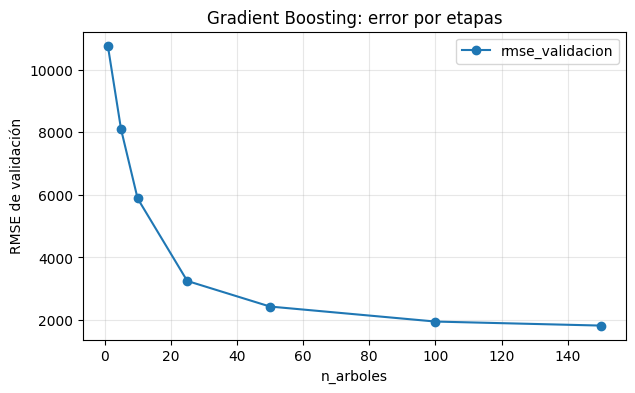

In [18]:
tabla_etapas.plot(
    x="n_arboles",
    y="rmse_validacion",
    marker="o",
    figsize=(7, 4),
    title="Gradient Boosting: error por etapas"
)
plt.ylabel("RMSE de validación")
plt.grid(alpha=0.3)
plt.show()

# 14. Comparar calidad y costo

Ahora ponemos todos los experimentos en una misma tabla.

La selección se hace usando **validación**.

In [19]:
resultados = [
    resultado_dummy,
    resultado_lineal,
    *resultados_sgd,
    resultado_boosting
]

comparacion = pd.DataFrame([
    {
        k: v
        for k, v in resultado.items()
        if k != "estimador"
    }
    for resultado in resultados
]).sort_values("rmse_validacion")

comparacion_mostrar = comparacion.copy()

for columna in [
    "rmse_validacion",
    "r2_validacion",
    "tiempo_entrenamiento_seg",
    "tiempo_prediccion_seg"
]:
    comparacion_mostrar[columna] = (
        comparacion_mostrar[columna].round(5)
    )

comparacion_mostrar

,modelo,rmse_validacion,r2_validacion,tiempo_entrenamiento_seg,tiempo_prediccion_seg
5,Gradient Boosting,"1,815.26",0.98,1.02,0.01
2,SGD eta0=0.0001,"3,497.27",0.91,0.06,0.00
1,Regresión lineal,"3,499.54",0.91,0.02,0.00
3,SGD eta0=0.001,"3,510.95",0.91,0.02,0.00
4,SGD eta0=0.01,"3,843.51",0.89,0.01,0.00
0,Dummy: media,"11,610.48",-0.00,0.00,0.00


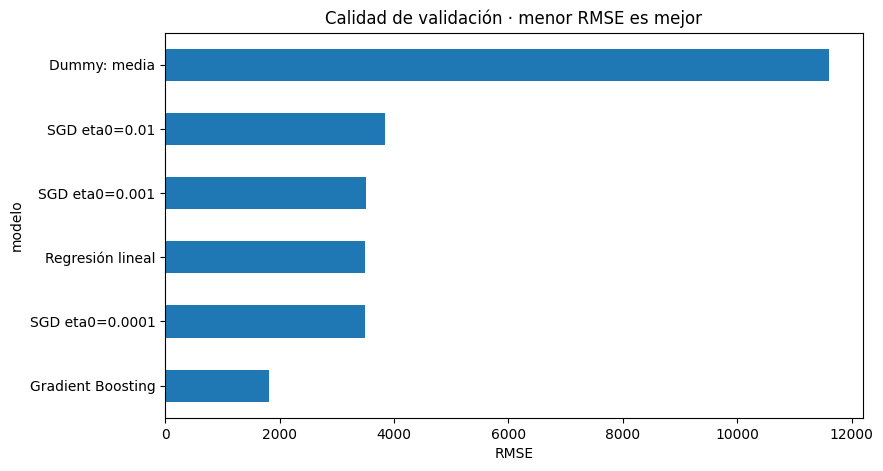

In [20]:
comparacion_mostrar.set_index("modelo")[
    "rmse_validacion"
].sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    title="Calidad de validación · menor RMSE es mejor"
)
plt.xlabel("RMSE")
plt.show()

## Pregunta de decisión

No mires únicamente la primera fila.

Para Rusty Bargain comenta:

- ¿cuánto mejora el mejor modelo respecto al Dummy?
- ¿el incremento en calidad justifica el tiempo?
- ¿qué modelo parece un buen equilibrio?

# 15. Seleccionar el modelo final

Elegiremos automáticamente el modelo con menor RMSE de validación.

Después abriremos test **una sola vez**.

In [21]:
mejor_nombre = comparacion.iloc[0]["modelo"]

mejor_resultado = next(
    resultado
    for resultado in resultados
    if resultado["modelo"] == mejor_nombre
)

mejor_modelo = mejor_resultado["estimador"]

if (
    mejor_nombre == "Regresión lineal"
    or mejor_nombre.startswith("SGD")
):
    X_test_modelo = X_test_escalado
else:
    X_test_modelo = X_test

predicciones_test = mejor_modelo.predict(X_test_modelo)

rmse_test = calcular_rmse(
    y_test,
    predicciones_test
)
r2_test = r2_score(
    y_test,
    predicciones_test
)

print("Modelo seleccionado:", mejor_nombre)
print("RMSE test:", round(rmse_test, 2))
print("R² test:", round(r2_test, 4))

Modelo seleccionado: Gradient Boosting
RMSE test: 1775.49
R² test: 0.9738


# 16. Revisar ejemplos de predicción

Una métrica resume cientos de casos.

También es útil inspeccionar algunos ejemplos individuales.

In [22]:
revision = pd.DataFrame({
    "precio_real": y_test.values,
    "precio_predicho": predicciones_test
})

revision["error_absoluto"] = (
    revision["precio_real"] -
    revision["precio_predicho"]
).abs()

revision.head(10)

,precio_real,precio_predicho,error_absoluto
0,20979,"19,408.09","1,570.91"
1,22910,"23,435.13",525.13
2,23017,"22,614.24",402.76
3,22143,"23,424.65","1,281.65"
4,400,651.75,251.75
5,400,542.36,142.36
6,400,"1,530.28","1,130.28"
7,400,480.62,80.62
8,20972,"21,829.51",857.51
9,5360,"4,289.89","1,070.11"


In [23]:
revision.sort_values(
    "error_absoluto",
    ascending=False
).head(10)

,precio_real,precio_predicho,error_absoluto
558,33203,"26,064.34","7,138.66"
519,20164,"13,500.90","6,663.10"
101,8351,"1,780.30","6,570.70"
181,13171,"19,729.02","6,558.02"
374,38346,"31,790.73","6,555.27"
234,400,"6,521.54","6,121.54"
616,14406,"8,691.90","5,714.10"
482,10284,"15,724.81","5,440.81"
431,32123,"27,028.01","5,094.99"
313,8072,"2,997.64","5,074.36"


# 17. Recomendación para Rusty Bargain

Una recomendación técnica debe conectar el resultado con el negocio.

In [24]:
fila_mejor = comparacion_mostrar.iloc[0]

print("RECOMENDACIÓN PRELIMINAR")
print()
print(
    f"El modelo seleccionado mediante validación fue "
    f"'{mejor_nombre}'. "
    f"En el conjunto de test obtuvo un RMSE aproximado de "
    f"{rmse_test:,.2f} y un R² de {r2_test:.3f}. "
    f"Durante la comparación, su entrenamiento tomó aproximadamente "
    f"{fila_mejor['tiempo_entrenamiento_seg']} segundos y su predicción "
    f"{fila_mejor['tiempo_prediccion_seg']} segundos sobre validación. "
    f"Antes de llevarlo a producción revisaríamos los errores extremos, "
    f"probaríamos más hiperparámetros y mediríamos latencia con un volumen "
    f"más parecido al tráfico real de la aplicación."
)

RECOMENDACIÓN PRELIMINAR

El modelo seleccionado mediante validación fue 'Gradient Boosting'. En el conjunto de test obtuvo un RMSE aproximado de 1,775.49 y un R² de 0.974. Durante la comparación, su entrenamiento tomó aproximadamente 1.02363 segundos y su predicción 0.00712 segundos sobre validación. Antes de llevarlo a producción revisaríamos los errores extremos, probaríamos más hiperparámetros y mediríamos latencia con un volumen más parecido al tráfico real de la aplicación.


# 18. Errores frecuentes del proyecto

| Situación | Problema |
|---|---|
| Escalar antes de separar train/test | Fuga de información |
| Ajustar hiperparámetros mirando test | Test deja de ser evaluación final |
| Comparar RMSE calculados en datasets distintos | Comparación inválida |
| Elegir solo por velocidad | Puede sacrificar demasiada calidad |
| Elegir solo por RMSE | Puede ignorar restricciones de producción |
| Asumir que una tasa mayor en SGD es mejor | Puede volver inestable el aprendizaje |
| Escalar árboles “porque siempre se escala” | Transformación innecesaria |

# 19. Validación final

Responde:

1. ¿por qué el problema es de regresión?
2. ¿por qué usamos un Dummy?
3. ¿qué conjunto utilizamos para elegir el modelo?
4. ¿por qué escalamos para SGD?
5. ¿por qué Gradient Boosting no necesita ese escalado?
6. ¿qué tres criterios pidió Rusty Bargain?
7. ¿por qué test debe abrirse al final?

<details>
<summary><strong>Respuestas esperadas</strong></summary>

1. Porque `Price` es numérico.  
2. Para tener una referencia mínima.  
3. Validación.  
4. Porque las diferencias de escala pueden dificultar las actualizaciones por gradiente.  
5. Porque los árboles realizan divisiones por umbrales y no dependen de distancias o magnitudes de gradiente de la misma forma.  
6. Calidad, tiempo de entrenamiento y tiempo de predicción.  
7. Para mantener una evaluación final independiente de las decisiones de selección.

</details>

# 20. Cierre

El objetivo del sprint no es concluir que existe un “mejor algoritmo universal”.

El aprendizaje importante es construir un proceso:

**problema → datos → preparación → baseline → experimentos → validación → costo → test → recomendación**

En métodos numéricos, la calidad de una solución y el costo de encontrarla forman parte de la misma conversación.